# Giai đoạn 3: Phân tích khám phá dữ liệu (EDA)

Notebook trả lời 10 câu hỏi trong kế hoạch (`docs/Projects.md`). Mỗi câu gồm số liệu, biểu đồ (lưu vào `reports/figures/`) và kết luận cho mô hình. Kết quả tổng hợp nằm trong `docs/EDA.md`.

Chạy lại từ đầu: `jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb`

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.stattools import acf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

# Chart style: reference palette of the dataviz guide (light surface), categorical slots in fixed order.
C = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "s4": "#eda100",
     "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
     "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb"}
SEQ_BLUE = ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "font.family": "Segoe UI", "font.size": 10,
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "text.color": C["ink"],
    "lines.linewidth": 1.5, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 0. Chuẩn bị dữ liệu

- Ghép 3 bảng theo `date` trên **lịch đầy đủ** từ 28/05/2023 đến 10/11/2026. 9 ngày EVN không đăng bài vẫn có dòng, nhưng số liệu EVN để trống.
- **Ngày "bình thường"** dùng làm mốc so sánh: thứ Hai–thứ Sáu, không phải ngày nghỉ, cách Tết hơn 10 ngày.
- **Mức nền ngắn hạn** (`*_level`): trung vị trượt 29 ngày của các ngày bình thường. **Tỉ lệ** `*_ratio` = giá trị / mức nền. Tỉ lệ này loại bỏ được xu hướng và mùa vụ, nên dùng để đo hiệu ứng thứ, lễ và Tết.
- **Xu hướng dài hạn** (`*_trend`): hồi quy log(y) theo thời gian trên các ngày bình thường. `*_detr` = giá trị / xu hướng, chỉ loại bỏ tăng trưởng, còn giữ nguyên mùa vụ và ảnh hưởng của thời tiết. Dùng cho câu 4 và câu 5.

In [2]:
evn = pd.read_csv(DATA / "evn_daily.csv", parse_dates=["date"])
wx = pd.read_csv(DATA / "weather.csv", parse_dates=["date"])
cal = pd.read_csv(DATA / "calendar.csv", parse_dates=["date"])

days = pd.DataFrame({"date": pd.date_range(evn["date"].min(), evn["date"].max())})
df = days.merge(evn, how="left").merge(wx, how="left").merge(cal, how="left").set_index("date")
df["has_post"] = df["article_id"].notna()
normal = (df["dow"] < 5) & (df["is_day_off"] == 0) & (df["tet_offset"].abs() > 10)
df["normal"] = normal

TARGETS = ["pmax_mw", "energy_mkwh"]
t_years = (df.index - df.index[0]).days / 365.25
growth = {}
for col in TARGETS:
    base = df[col].where(normal)
    df[f"{col}_level"] = base.rolling(29, center=True, min_periods=10).median().interpolate(limit_direction="both")
    df[f"{col}_ratio"] = df[col] / df[f"{col}_level"]
    ok = base.notna()
    b, a = np.polyfit(t_years[ok], np.log(base[ok]), 1)
    df[f"{col}_trend"] = np.exp(a + b * t_years)
    df[f"{col}_detr"] = df[col] / df[f"{col}_trend"]
    growth[col] = np.exp(b) - 1

print(f"{len(df)} ngày lịch, {df['has_post'].sum()} ngày có bài, {normal.sum()} ngày bình thường")
print({k: f"{v:.1%}/năm" for k, v in growth.items()})

1263 ngày lịch, 1254 ngày có bài, 834 ngày bình thường
{'pmax_mw': '7.4%/năm', 'energy_mkwh': '7.6%/năm'}


## Câu 1 và 9: Xu hướng và tăng trưởng

Pmax và sản lượng thay đổi thế nào trong 2023–2026? Tăng bao nhiêu mỗi năm?

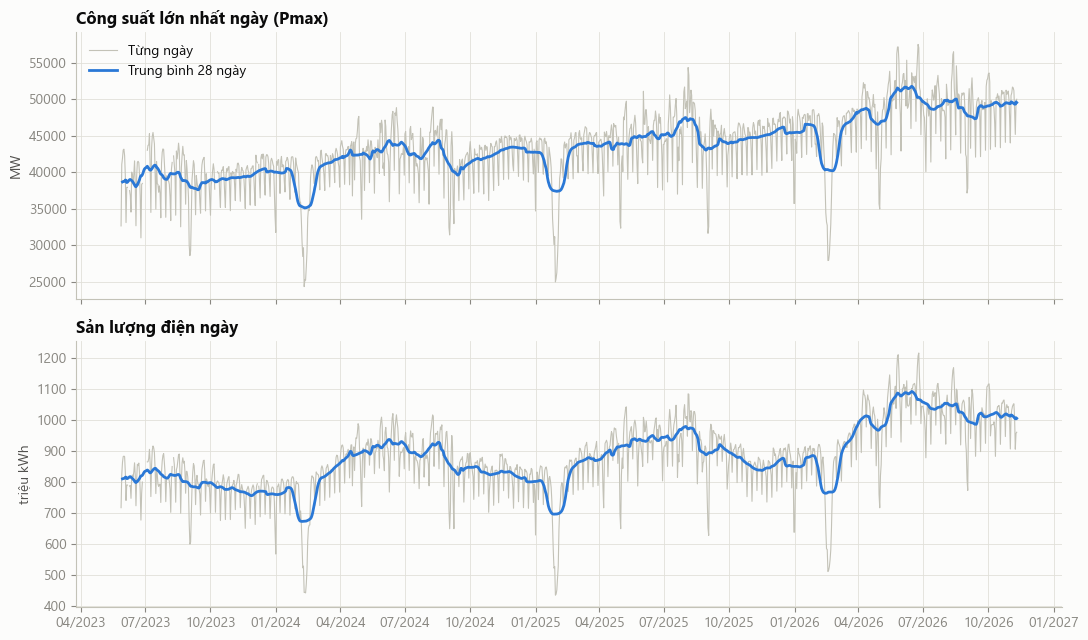

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, col, title, unit in [(axes[0], "pmax_mw", "Công suất lớn nhất ngày (Pmax)", "MW"),
                             (axes[1], "energy_mkwh", "Sản lượng điện ngày", "triệu kWh")]:
    ax.plot(df.index, df[col], color=C["axis"], lw=0.8, label="Từng ngày")
    ax.plot(df.index, df[col].rolling(28, center=True, min_periods=14).mean(), color=C["s1"], lw=2, label="Trung bình 28 ngày")
    ax.set_title(title)
    ax.set_ylabel(unit)
axes[0].legend(loc="upper left")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
fig.tight_layout()
save(fig, "01_trend")

Tăng trưởng trung bình so với cùng tháng năm trước:


,"Pmax TB tháng, tăng so cùng kỳ (%)","Sản lượng TB tháng, tăng so cùng kỳ (%)",Số tháng so sánh
year,,,
2024,8.2,8.8,8
2025,5.8,4.3,12
2026,9.3,11.3,11


Tăng trưởng theo xu hướng log-tuyến tính (ngày bình thường): {'pmax_mw': '7.4%', 'energy_mkwh': '7.6%'}


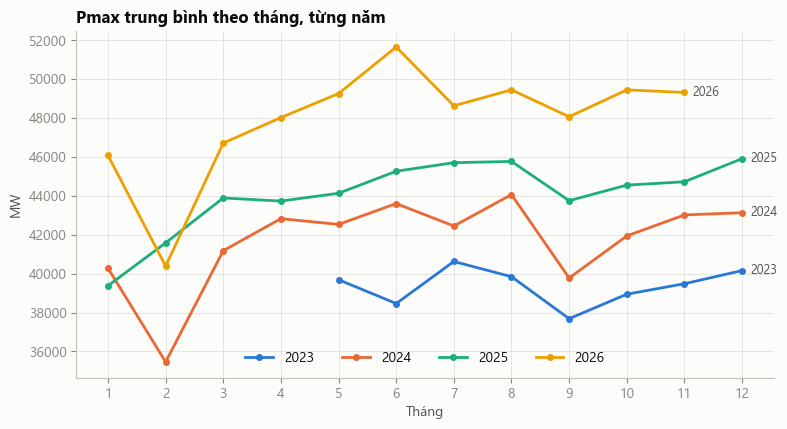

In [4]:
m = df[TARGETS].resample("MS").mean()
m["year"], m["month"] = m.index.year, m.index.month
pmax_m = m.pivot(index="month", columns="year", values="pmax_mw")
energy_m = m.pivot(index="month", columns="year", values="energy_mkwh")
yoy = pd.DataFrame({
    "Pmax TB tháng, tăng so cùng kỳ (%)": (pmax_m.pct_change(axis=1, fill_method=None) * 100).stack().groupby(level=1).mean(),
    "Sản lượng TB tháng, tăng so cùng kỳ (%)": (energy_m.pct_change(axis=1, fill_method=None) * 100).stack().groupby(level=1).mean(),
    "Số tháng so sánh": pmax_m.pct_change(axis=1, fill_method=None).stack().groupby(level=1).size(),
}).round(1)
print("Tăng trưởng trung bình so với cùng tháng năm trước:")
display(yoy)
print("Tăng trưởng theo xu hướng log-tuyến tính (ngày bình thường):", {k: f"{v:.1%}" for k, v in growth.items()})

colors = {2023: C["s1"], 2024: C["s2"], 2025: C["s3"], 2026: C["s4"]}
fig, ax = plt.subplots(figsize=(9, 4.5))
for y in pmax_m.columns:
    s = pmax_m[y].dropna()
    ax.plot(s.index, s.values, color=colors[y], lw=2, marker="o", ms=4, label=str(y))
    ax.annotate(str(y), (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=C["ink2"], fontsize=9)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Tháng")
ax.set_ylabel("MW")
ax.set_title("Pmax trung bình theo tháng, từng năm")
ax.legend(loc="lower center", ncol=4)
save(fig, "02_monthly_by_year")

**Đọc kết quả:** xem bảng và biểu đồ ở trên. Kết luận được ghi trong `docs/EDA.md`.

## Câu 2: Hiệu ứng thứ trong tuần

Phụ tải từng thứ khác nhau bao nhiêu so với ngày làm việc? Chỉ xét các ngày không nghỉ lễ và cách Tết hơn 10 ngày, dùng tỉ lệ so với mức nền.

pmax_mw_ratio              energy_mkwh_ratio             
            mean    std count              mean    std count
T2         1.000  0.031   163             0.978  0.032   163
T3         1.002  0.033   167             1.003  0.034   168
T4         1.002  0.039   164             1.006  0.041   164
T5         1.003  0.034   164             1.009  0.034   164
T6         0.995  0.034   167             1.005  0.034   167
T7         0.953  0.040   169             0.974  0.035   169
CN         0.865  0.039   169             0.880  0.038   170

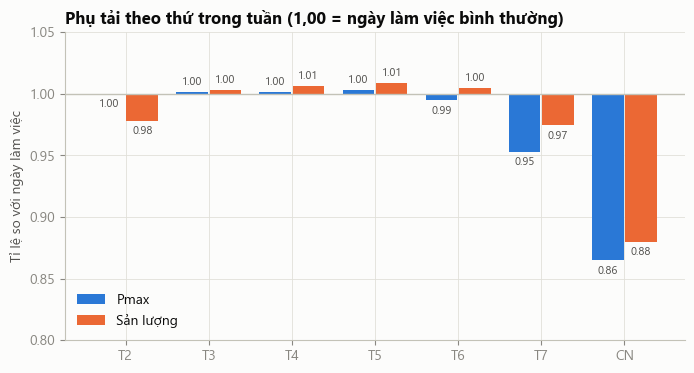

In [5]:
wk = df[(df["is_holiday"] == 0) & (df["tet_offset"].abs() > 10)]
names = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
dow_tab = wk.groupby("dow")[["pmax_mw_ratio", "energy_mkwh_ratio"]].agg(["mean", "std", "count"]).round(3)
dow_tab.index = names
display(dow_tab)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(7)
w = 0.38
for i, (col, lab, c) in enumerate([("pmax_mw_ratio", "Pmax", C["s1"]), ("energy_mkwh_ratio", "Sản lượng", C["s2"])]):
    v = wk.groupby("dow")[col].mean()
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), v.values - 1, width=w, bottom=1, color=c, label=lab)
ax.axhline(1, color=C["axis"], lw=1)
ax.set_xticks(x, names)
ax.set_ylim(0.8, 1.05)
ax.set_ylabel("Tỉ lệ so với ngày làm việc")
ax.set_title("Phụ tải theo thứ trong tuần (1,00 = ngày làm việc bình thường)")
ax.legend(loc="lower left")
for i, col in enumerate(["pmax_mw_ratio", "energy_mkwh_ratio"]):
    for xi, v in zip(x, wk.groupby("dow")[col].mean()):
        up = v >= 1
        ax.annotate(f"{v:.2f}", (xi + (i - 0.5) * (w + 0.02), v), xytext=(0, 3 if up else -3), textcoords="offset points",
                    ha="center", va="bottom" if up else "top", fontsize=8, color=C["ink2"])
save(fig, "03_weekday")

## Câu 3 và 10: Ngày lễ và Tết

Phụ tải giảm bao nhiêu vào ngày lễ, và ảnh hưởng kéo dài mấy ngày trước và sau? So sánh 3 lần Tết 2024, 2025, 2026.

In [6]:
hol = df[(df["is_holiday"] == 1) & (df["tet_offset"].abs() > 10)][["holiday_name", "dow", "off_block_len", "pmax_mw_ratio", "energy_mkwh_ratio"]]
print("Ngày lễ ngoài Tết:")
display(hol.round(3))
print("Trung bình:", hol[["pmax_mw_ratio", "energy_mkwh_ratio"]].mean().round(3).to_dict())

edge = df[(df["is_holiday"] == 0) & (df["tet_offset"].abs() > 10) & (df["dow"] < 5)]
print("Ngày làm việc ngay trước / sau một kỳ nghỉ (thứ Hai–Sáu):")
display(edge.groupby(["is_pre_day_off", "is_post_day_off"])["energy_mkwh_ratio"].agg(["mean", "count"]).round(3))

Ngày lễ ngoài Tết:


,holiday_name,dow,off_block_len,pmax_mw_ratio,energy_mkwh_ratio
date,,,,,
2023-09-01,Quốc khánh,4,4,0.741,0.804
2023-09-02,Quốc khánh,5,4,0.708,0.726
2023-09-04,Quốc khánh (nghỉ bù),0,4,0.848,0.841
2024-01-01,Tết Dương lịch,0,3,0.764,0.723
2024-04-18,Ngày Giỗ Tổ Hùng Vương,3,1,0.843,0.867
2024-04-29,Ngày nghỉ (thay cho ngày 04/05/2024),0,5,0.950,0.950
2024-04-30,Ngày Chiến thắng,1,5,0.853,0.859
2024-05-01,Ngày Quốc tế Lao động,2,5,0.765,0.784
2024-09-02,Quốc khánh,0,4,0.719,0.709


Trung bình: {'pmax_mw_ratio': 0.782, 'energy_mkwh_ratio': 0.779}
Ngày làm việc ngay trước / sau một kỳ nghỉ (thứ Hai–Sáu):


mean  count
is_pre_day_off is_post_day_off              
0              0                1.008    484
               1                0.977    172
1              0                1.003    168
               1                0.931      2

,Mùng 1,Tỉ lệ thấp nhất,Ngày thấp nhất (so Mùng 1),"Ngày làm việc cuối còn ≥ 0,95 trước Tết","Ngày làm việc đầu tiên ≥ 0,95 sau Tết"
Tết,,,,,
2024,2024-02-10,0.542,2,-8,10
2025,2025-01-29,0.514,0,-7,13
2026,2026-02-17,0.559,0,-7,9


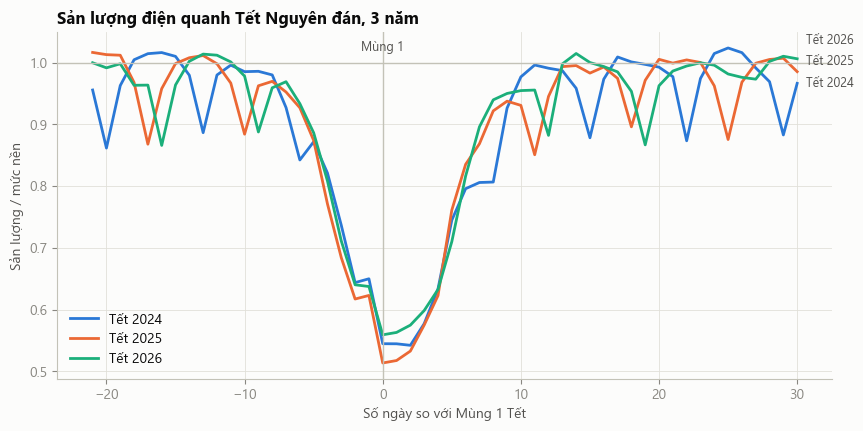

In [7]:
win = df[df["tet_offset"].between(-21, 30)].copy()
win["tet_year"] = (win.index - pd.to_timedelta(win["tet_offset"], unit="D")).dt.year
tet = win.pivot_table(index="tet_offset", columns="tet_year", values="energy_mkwh_ratio")
tet = tet[[y for y in tet.columns if tet[y].notna().sum() > 40]]

# Start / recovery are read on Monday-Friday only: a plain Sunday already sits near 0,88.
wd = win[win["dow"] < 5].pivot_table(index="tet_offset", columns="tet_year", values="energy_mkwh_ratio")
rows = []
for y in tet.columns:
    s, w = tet[y], wd[y].dropna()
    before, after = w.loc[:0], w.loc[1:]
    last_ok = before[before >= 0.95].index.max()
    first_ok = after[after >= 0.95].index.min()
    rows.append({"Tết": y, "Mùng 1": df.index[df["tet_offset"].eq(0) & (df.index.year == y)][0].date(),
                 "Tỉ lệ thấp nhất": round(s.min(), 3), "Ngày thấp nhất (so Mùng 1)": int(s.idxmin()),
                 "Ngày làm việc cuối còn ≥ 0,95 trước Tết": int(last_ok),
                 "Ngày làm việc đầu tiên ≥ 0,95 sau Tết": int(first_ok) if pd.notna(first_ok) else None})
tet_tab = pd.DataFrame(rows).set_index("Tết")
display(tet_tab)

fig, ax = plt.subplots(figsize=(10, 4.5))
ends = []
for y, c in zip(tet.columns, [C["s1"], C["s2"], C["s3"]]):
    ax.plot(tet.index, tet[y], color=c, lw=2, label=f"Tết {y}")
    last = tet[y].dropna()
    ends.append([last.values[-1], last.index[-1], f"Tết {y}"])
ends.sort()
for i in range(1, len(ends)):  # keep end labels at least 0.035 apart
    ends[i][0] = max(ends[i][0], ends[i - 1][0] + 0.035)
for yv, xv, lab in ends:
    ax.annotate(lab, (xv, yv), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=C["ink2"])
ax.axvline(0, color=C["axis"], lw=1)
ax.axhline(1, color=C["axis"], lw=1)
ax.annotate("Mùng 1", (0, 1.02), ha="center", fontsize=9, color=C["ink2"])
ax.set_xlabel("Số ngày so với Mùng 1 Tết")
ax.set_ylabel("Sản lượng / mức nền")
ax.set_title("Sản lượng điện quanh Tết Nguyên đán, 3 năm")
ax.legend(loc="lower left")
save(fig, "04_tet_profile")

## Câu 4: Nhiệt độ và phụ tải

Quan hệ là tuyến tính hay phi tuyến? Miền nào ảnh hưởng mạnh nhất? Giả định trọng số 0,45/0,10/0,45 có hợp lý không?

Dùng `pmax_mw_detr` (đã loại bỏ tăng trưởng) của các ngày bình thường, và thời tiết **thực tế** (`obs_`).

In [8]:
nd = df[normal & df["pmax_mw_detr"].notna()]
corr = pd.DataFrame({
    reg: {v: nd["pmax_mw_detr"].corr(nd[f"obs_{v}_{reg}"]) for v in ["tmax", "tmean", "tmin", "app_tmax", "rh", "rad"]}
    for reg in ["hn", "dn", "hcm", "vn"]
}).round(3)
print("Tương quan Pearson giữa Pmax (đã khử xu hướng) và thời tiết thực tế, ngày bình thường:")
display(corr)

# Implied regional weights: regress detrended Pmax on the three regional Tmax (informal check of REGION_WEIGHTS).
X = np.column_stack([np.ones(len(nd))] + [nd[f"obs_tmax_{r}"] for r in ["hn", "dn", "hcm"]])
coef, *_ = np.linalg.lstsq(X, nd["pmax_mw_detr"].values, rcond=None)
implied = pd.Series(coef[1:], index=["hn", "dn", "hcm"])
print("Hệ số hồi quy theo Tmax từng miền:", implied.round(4).to_dict())
print("Trọng số ngầm định (chuẩn hóa tổng = 1):", (implied / implied.sum()).round(2).to_dict())

Tương quan Pearson giữa Pmax (đã khử xu hướng) và thời tiết thực tế, ngày bình thường:


,hn,dn,hcm,vn
tmax,0.448,0.510,0.292,0.549
tmean,0.424,0.468,0.395,0.501
tmin,0.372,0.367,0.360,0.401
app_tmax,0.442,0.458,0.362,0.491
rh,-0.060,-0.493,-0.090,-0.167
rad,0.441,0.429,0.285,0.541


Hệ số hồi quy theo Tmax từng miền: {'hn': 0.0017, 'dn': 0.0033, 'hcm': 0.0058}
Trọng số ngầm định (chuẩn hóa tổng = 1): {'hn': 0.16, 'dn': 0.3, 'hcm': 0.54}


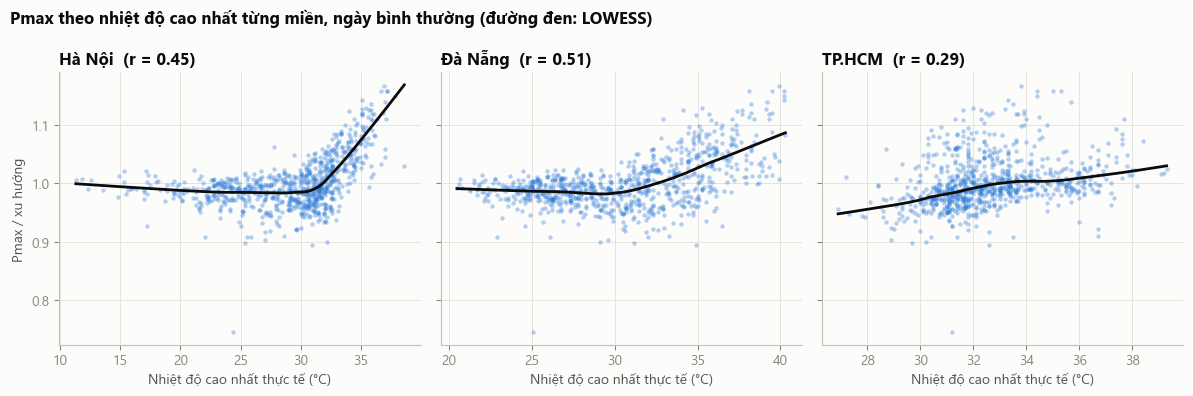

Pmax / xu hướng trung bình theo khoảng Tmax Hà Nội:


,mean,count
obs_tmax_hn,,
"(0, 20]",0.992,43
"(20, 25]",0.982,125
"(25, 30]",0.981,219
"(30, 35]",1.008,389
"(35, 45]",1.093,49


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, reg, name in zip(axes, ["hn", "dn", "hcm"], ["Hà Nội", "Đà Nẵng", "TP.HCM"]):
    x, y = nd[f"obs_tmax_{reg}"], nd["pmax_mw_detr"]
    ax.scatter(x, y, s=10, color=C["s1"], alpha=0.35, linewidths=0)
    fit = lowess(y, x, frac=0.4)
    ax.plot(fit[:, 0], fit[:, 1], color=C["ink"], lw=2)
    ax.set_title(f"{name}  (r = {x.corr(y):.2f})")
    ax.set_xlabel("Nhiệt độ cao nhất thực tế (°C)")
axes[0].set_ylabel("Pmax / xu hướng")
fig.suptitle("Pmax theo nhiệt độ cao nhất từng miền, ngày bình thường (đường đen: LOWESS)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "05_temperature")

# Slope of the LOWESS curve by temperature band (Hà Nội): is the effect stronger when hot?
x, y = nd["obs_tmax_hn"], nd["pmax_mw_detr"]
bands = pd.cut(x, [0, 20, 25, 30, 35, 45])
print("Pmax / xu hướng trung bình theo khoảng Tmax Hà Nội:")
display(y.groupby(bands, observed=True).agg(["mean", "count"]).round(3))

## Câu 5: Tự tương quan

Phụ tải hôm nay liên quan đến các ngày trước đến mức nào? Chọn biến lag nào? Lưu ý **lag nhỏ nhất dùng được là 2** (mục 2.5 `Data.md`).

,ACF Pmax/xu hướng,ACF Pmax/mức nền
1,0.636,0.593
2,0.406,0.335
3,0.301,0.218
6,0.265,0.176
7,0.474,0.407
14,0.332,0.280
21,0.283,0.272
28,0.281,0.266


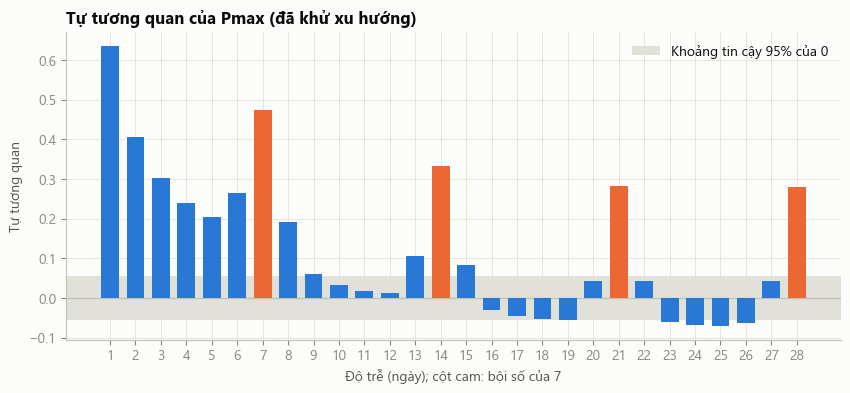

In [10]:
s = df["pmax_mw_detr"].interpolate(limit=3)
s = s.loc[s.first_valid_index():s.last_valid_index()]
lags = 28
a = acf(s, nlags=lags, missing="drop")
r = df["pmax_mw_ratio"].interpolate(limit=3).dropna()
a_ratio = acf(r, nlags=lags, missing="drop")
acf_tab = pd.DataFrame({"ACF Pmax/xu hướng": a, "ACF Pmax/mức nền": a_ratio}).round(3)
display(acf_tab.loc[[1, 2, 3, 6, 7, 14, 21, 28]])

fig, ax = plt.subplots(figsize=(10, 4))
k = np.arange(1, lags + 1)
ax.bar(k, a[1:], width=0.7, color=[C["s1"] if i % 7 else C["s2"] for i in k], zorder=3)
ax.axhline(0, color=C["axis"], lw=1)
ci = 1.96 / np.sqrt(len(s))
ax.axhspan(-ci, ci, color=C["grid"], lw=0, zorder=1, label="Khoảng tin cậy 95% của 0")
ax.legend(loc="upper right")
ax.set_xticks(k)
ax.set_xlabel("Độ trễ (ngày); cột cam: bội số của 7")
ax.set_ylabel("Tự tương quan")
ax.set_title("Tự tương quan của Pmax (đã khử xu hướng)")
save(fig, "06_acf")

## Câu 6: Giờ xảy ra Pmax

Giờ Pmax thay đổi theo mùa và theo năm thế nào? Có dịch chuyển do điện mặt trời mái nhà không?

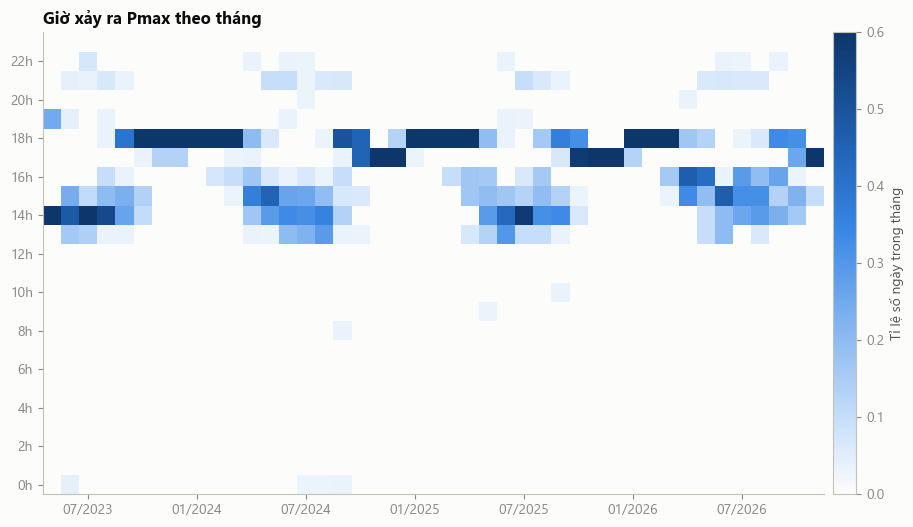

Tỉ lệ ngày theo khung giờ Pmax, theo tháng trong năm (2023–2026):


band,trước 12h,12h–17h,từ 17h
month,,,
1,0.00,0.00,1.00
2,0.00,0.02,0.98
3,0.00,0.14,0.86
4,0.00,0.64,0.36
5,0.01,0.80,0.19
6,0.01,0.88,0.11
7,0.01,0.88,0.12
8,0.01,0.85,0.15
9,0.02,0.51,0.47


band,trước 12h,12h–17h,từ 17h
period,,,
04/06/2024–nay,0.007,0.443,0.551
30/05/2023–03/06/2024,0.003,0.432,0.565


Từ 04/06/2024: giờ Pmax theo hai cách tính khác nhau ở 19.3% số ngày; Pmax đầu cực cao hơn thương phẩm trung bình 309 MW


In [11]:
h = pd.to_datetime(df["pmax_time"], format="%H:%M", errors="coerce")
df["pmax_hour"] = h.dt.hour + h.dt.minute / 60
ym = df["pmax_hour"].dropna()
heat = pd.crosstab(np.floor(ym).astype(int), ym.index.to_period("M"), normalize="columns").reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 6))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blue", SEQ_BLUE)
im = ax.pcolormesh(np.arange(heat.shape[1] + 1), np.arange(heat.shape[0] + 1), heat.values, cmap=cmap, vmin=0, vmax=0.6)
ax.set_yticks(np.arange(0, 24, 2) + 0.5, [f"{x}h" for x in range(0, 24, 2)])
ticks = [i for i, p in enumerate(heat.columns) if p.month in (1, 7)]
ax.set_xticks(np.array(ticks) + 0.5, [heat.columns[i].strftime("%m/%Y") for i in ticks])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Tỉ lệ số ngày trong tháng")
ax.set_title("Giờ xảy ra Pmax theo tháng")
save(fig, "07_pmax_hour")

by_month = pd.DataFrame({"month": df.index.month, "hour": df["pmax_hour"]}).dropna()
by_month["band"] = pd.cut(by_month["hour"], [0, 12, 17, 24], right=False, labels=["trước 12h", "12h–17h", "từ 17h"])
print("Tỉ lệ ngày theo khung giờ Pmax, theo tháng trong năm (2023–2026):")
display(pd.crosstab(by_month["month"], by_month["band"], normalize="index").round(2))

period = np.where(df.index < "2024-06-04", "30/05/2023–03/06/2024", "04/06/2024–nay")
share = pd.DataFrame({"period": period, "hour": df["pmax_hour"]}).dropna()
share["band"] = pd.cut(share["hour"], [0, 12, 17, 24], right=False, labels=["trước 12h", "12h–17h", "từ 17h"])
display(pd.crosstab(share["period"], share["band"], normalize="index").round(3))

both = df[["pmax_time", "pmax_time_dc", "pmax_mw", "pmax_mw_dc"]].dropna()
print(f"Từ 04/06/2024: giờ Pmax theo hai cách tính khác nhau ở {(both.pmax_time != both.pmax_time_dc).mean():.1%} số ngày; "
      f"Pmax đầu cực cao hơn thương phẩm trung bình {(both.pmax_mw_dc - both.pmax_mw).mean():.0f} MW")

## Câu 7: Ngày bất thường

Ngoài lễ và Tết, có ngày nào phụ tải lệch mạnh so với mức nền không? Tiêu chí: ngày thứ Hai–Sáu không nghỉ, |tỉ lệ − 1| > 8%.

In [12]:
cand = df[(df["dow"] < 5) & (df["is_holiday"] == 0) & (df["tet_offset"].abs() > 10)]
out = cand[(cand["energy_mkwh_ratio"] - 1).abs() > 0.08][["dow", "pmax_mw", "energy_mkwh", "pmax_mw_ratio", "energy_mkwh_ratio", "obs_tmax_hn", "obs_precip_hn", "obs_precip_hcm", "qc_same_as_adjacent"]]
display(out.round(3))
print(f"{len(out)} ngày bất thường / {len(cand)} ngày làm việc")
print("Cờ |qc_energy_diff| > 2:", df.index[df["qc_energy_diff"].abs() > 2].strftime("%d/%m/%Y").tolist())
print("Cờ qc_same_as_adjacent (số liệu trùng y hệt ngày kề):", df.index[df["qc_same_as_adjacent"] == 1].strftime("%d/%m/%Y").tolist())

,dow,pmax_mw,energy_mkwh,pmax_mw_ratio,energy_mkwh_ratio,obs_tmax_hn,obs_precip_hn,obs_precip_hcm,qc_same_as_adjacent
date,,,,,,,,,
2023-06-26,0,38344.4,763.0,0.928,0.895,26.5,9.1,0.3,0.0
2023-07-19,2,38365.3,792.8,0.897,0.919,30.2,6.5,14.3,0.0
2024-05-29,2,47146.5,1008.7,1.085,1.093,34.6,0.6,20.8,0.0
2024-06-10,0,41289.9,857.4,0.892,0.884,30.6,43.7,10.2,0.0
2024-06-14,4,48363.4,1020.0,1.090,1.083,34.0,0.0,10.7,0.0
2024-10-28,0,42200.4,773.2,0.970,0.916,23.3,6.7,41.9,0.0
2025-05-09,4,49759.2,1041.8,1.073,1.080,33.0,7.7,1.4,0.0
2025-05-26,0,44236.1,883.9,0.960,0.920,27.9,0.0,6.0,0.0
2025-07-21,0,43469.2,887.9,0.910,0.891,31.4,35.0,5.4,0.0


26 ngày bất thường / 834 ngày làm việc
Cờ |qc_energy_diff| > 2: ['04/07/2023', '24/05/2024', '25/05/2024', '26/05/2024', '27/05/2024', '28/05/2024', '29/05/2024', '30/05/2024', '31/05/2024', '01/06/2024', '02/06/2024', '20/09/2025', '10/10/2025']
Cờ qc_same_as_adjacent (số liệu trùng y hệt ngày kề): ['05/06/2023', '06/06/2023', '23/08/2024', '24/08/2024', '28/02/2025', '01/03/2025', '04/07/2025', '05/07/2025', '31/12/2025', '01/01/2026', '30/01/2026', '31/01/2026', '15/03/2026', '16/03/2026']


## Câu 8: Baseline (mốc sai số cần vượt qua)

Các phương pháp đơn giản, **chỉ dùng thông tin có trước lúc dự báo** (lag ≥ 2):

| Tên | Dự báo cho ngày t |
|---|---|
| `lag2` | giá trị ngày t−2 (số liệu mới nhất có được) |
| `lag7` | giá trị ngày t−7 (cùng thứ tuần trước) |
| `mean_lag7_28` | trung bình t−7, t−14, t−21, t−28 (cùng thứ, 4 tuần) |
| `lag1` | giá trị ngày t−1, **không khả thi** trong thực tế, chỉ để tham khảo |

Đánh giá trên **12 tháng gần nhất** (11/11/2025 → 10/11/2026) và trên toàn bộ chuỗi, tách ngày thường và ngày lễ/Tết.

In [13]:
def mape(y, p):
    m = y.notna() & p.notna()
    return (np.abs(p[m] - y[m]) / y[m]).mean() * 100, int(m.sum())

special = (df["is_holiday"] == 1) | (df["tet_offset"].abs() <= 10)
last12 = df.index >= df.index[-1] - pd.Timedelta(days=364)
rows = []
for col in TARGETS:
    y = df[col]
    preds = {"lag1 (tham khảo)": y.shift(1), "lag2": y.shift(2), "lag7": y.shift(7),
             "mean_lag7_28": pd.concat([y.shift(k) for k in (7, 14, 21, 28)], axis=1).mean(axis=1, skipna=False)}
    for name, p in preds.items():
        r = {"biến": col, "baseline": name}
        for lab, mask in [("12 tháng: tất cả", last12), ("12 tháng: ngày thường", last12 & ~special),
                          ("12 tháng: lễ/Tết", last12 & special), ("toàn bộ", np.ones(len(df), bool))]:
            r[lab], _ = mape(y[mask], p[mask])
        rows.append(r)
base_tab = pd.DataFrame(rows).set_index(["biến", "baseline"]).round(2)
print("MAPE (%) của các baseline:")
display(base_tab)

MAPE (%) của các baseline:


12 tháng: tất cả  12 tháng: ngày thường  12 tháng: lễ/Tết  toàn bộ
biến        baseline                                                                            
pmax_mw     lag1 (tham khảo)              5.15                   5.01              6.73     5.35
            lag2                          7.20                   6.64             13.65     7.48
            lag7                          6.01                   4.37             25.01     5.85
            mean_lag7_28                  5.63                   4.01             24.37     5.54
energy_mkwh lag1 (tham khảo)              4.60                   4.39              7.04     4.87
            lag2                          6.44                   5.76             14.25     6.79
            lag7                          6.86                   5.03             28.08     6.54
            mean_lag7_28                  6.59                   4.85             26.78     6.35